# 08 — Stress Testing

**Goal:** apply hypothetical shock scenarios to the current portfolio and
quantify the impact. These are **not** predictions or historical replays —
they show "what if" outcomes for pre-defined or custom shocks.

In [1]:
import sys
from pathlib import Path
PROJECT_ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams["figure.figsize"] = (10, 5)

np.random.seed(42)

from notebooks.nb_utils import fetch_price_panel

TICKERS = ["AAPL", "MSFT", "GLD", "BND", "SPY"]
START = "2019-01-01"

price_panel, used_synthetic = fetch_price_panel(TICKERS, START)
returns_panel = price_panel.pct_change().dropna()
print(f"Loaded {price_panel.shape[0]} rows x {price_panel.shape[1]} tickers. Synthetic data: {used_synthetic}")
price_panel.tail()

Failed to get ticker 'GLD' reason: Expecting value: line 1 column 1 (char 0)


HTTP Error 403: Host not in allowlist: query2.finance.yahoo.com. Add this host to your network egress settings to allow access.


HTTP Error 403: Host not in allowlist: query1.finance.yahoo.com. Add this host to your network egress settings to allow access.


Failed to get ticker 'AAPL' reason: Expecting value: line 1 column 1 (char 0)


HTTP Error 403: Host not in allowlist: query2.finance.yahoo.com. Add this host to your network egress settings to allow access.


HTTP Error 403: Host not in allowlist: query1.finance.yahoo.com. Add this host to your network egress settings to allow access.


... (7 outputs left out)

['GLD', 'AAPL']: JSONDecodeError('Expecting value: line 1 column 1 (char 0)')


['SPY', 'MSFT', 'BND']: possibly delisted; no timezone found


[info] Live data unavailable (KeyError); using synthetic demo data instead.
Loaded 2004 rows x 5 tickers. Synthetic data: True


,AAPL,MSFT,GLD,BND,SPY
2026-08-31,229.681016,128.274867,119.914845,364.746718,107.728124
2026-09-01,227.093540,128.294744,120.000708,372.445526,106.711406
2026-09-02,229.155329,127.875189,121.085078,365.765614,106.991434
2026-09-03,232.958620,125.652809,122.697759,374.610608,107.656847
2026-09-04,232.705684,125.622649,120.900524,369.667262,106.661264


In [2]:
from src.risk.stress_testing import run_all_scenarios
from src.config import CONFIG

weights = pd.Series(1 / len(TICKERS), index=TICKERS)
portfolio_value = 100_000

# Map each ticker to a rough asset-class shock line, for illustration.
asset_class_map = {"AAPL": "equities", "MSFT": "equities", "SPY": "equities", "GLD": "gold", "BND": "bonds"}
holdings_by_class = weights.rename(index=lambda t: asset_class_map.get(t, "equities"))
holdings_by_class = holdings_by_class.groupby(level=0).sum()

results = run_all_scenarios(holdings_by_class, CONFIG["stress_scenarios"], portfolio_value)
summary = pd.DataFrame([{
    "scenario": r.scenario_name,
    "portfolio_loss_pct": r.portfolio_loss_pct,
    "new_value": r.portfolio_new_value,
} for r in results]).set_index("scenario")
summary

,portfolio_loss_pct,new_value
scenario,,
market_crash,-0.166,83400.0
inflation_shock,-0.080,92000.0
rate_shock,-0.100,90000.0


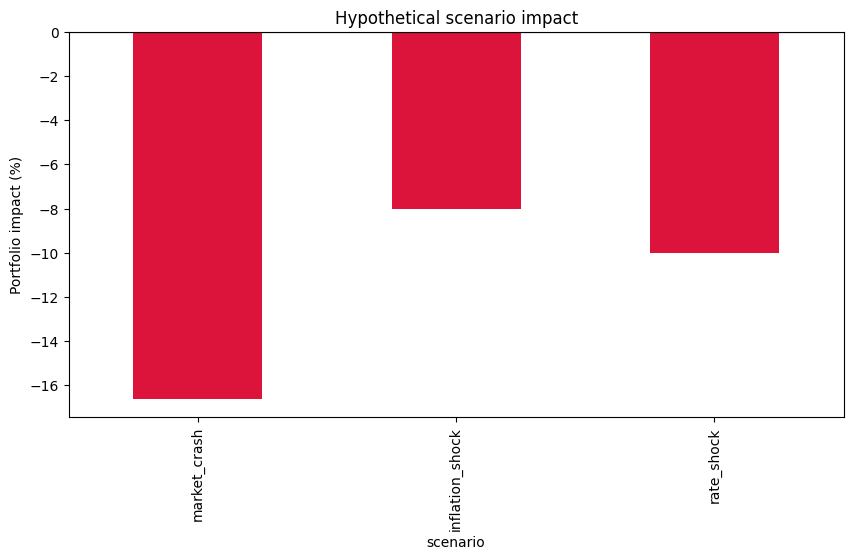

In [3]:
summary["portfolio_loss_pct"].mul(100).plot(kind="bar", color=["crimson" if x < 0 else "seagreen" for x in summary["portfolio_loss_pct"]])
plt.ylabel("Portfolio impact (%)")
plt.title("Hypothetical scenario impact")
plt.axhline(0, color="black", linewidth=0.8)
plt.show()

## Custom scenario

In [4]:
from src.risk.stress_testing import run_stress_test

custom_shock = {"equities": -0.20, "bonds": 0.03, "gold": 0.10}
custom_result = run_stress_test("tech_selloff_flight_to_safety", holdings_by_class, custom_shock, portfolio_value)
print(f"{custom_result.scenario_name}: {custom_result.portfolio_loss_pct:.1%} -> new value ${custom_result.portfolio_new_value:,.0f}")

tech_selloff_flight_to_safety: -9.4% -> new value $90,600


## Takeaways

- Stress testing complements VaR/CVaR/Monte Carlo: it answers 'what happens under this specific, named scenario' rather than 'what's the probability-weighted range of outcomes'.
- Continue to **09 — Market Regime Detection**.